In [1]:
# # FINAURA – Delhi Petrol Price Data Preprocessing

# This notebook performs complete preprocessing of the Delhi daily petrol price dataset.

# ## Preprocessing Steps
# 1. Data Loading
# 2. Data Inspection
# 3. Data Type Conversion
# 4. Missing Value Analysis
# 5. Duplicate Analysis
# 6. Date Sorting
# 7. Petrol Price Validation
# 8. Daily Price Change
# 9. Daily Return
# 10. Moving Averages
# 11. Rolling Volatility
# 12. Momentum
# 13. Previous Price
# 14. Next-Day Price Target
# 15. Leakage Check
# 16. Final Validation
# 17. Data Visualization
# 18. Export Processed Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [3]:
BASE_DIR = Path.cwd().parent

INPUT_FILE = BASE_DIR / "data" / "raw" / "delhi_petrol_raw.csv"
OUTPUT_FILE = BASE_DIR / "data" / "processed" / "delhi_petrol_processed.csv"

print("Input file:", INPUT_FILE)
print("Output file:", OUTPUT_FILE)

Input file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\raw\delhi_petrol_raw.csv
Output file: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\delhi_petrol_processed.csv


In [4]:
df = pd.read_csv(INPUT_FILE)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 3372
Columns: 3


,Date,City,Petrol_Price
0,2017-06-16,Delhi,65.4800
1,2017-06-17,Delhi,65.2300
2,2017-06-18,Delhi,64.9100
3,2017-06-19,Delhi,64.6500
4,2017-06-20,Delhi,64.5500


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3372 entries, 0 to 3371
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Date          3372 non-null   object 
 1   City          3372 non-null   object 
 2   Petrol_Price  3372 non-null   float64
dtypes: float64(1), object(2)
memory usage: 79.2+ KB


In [7]:
df.describe()

,Petrol_Price
count,3372.0000
mean,87.7145
std,11.6247
min,63.0600
25%,74.6300
50%,94.7700
75%,96.7200
max,110.0400


In [8]:
print(df.columns.tolist())

['Date', 'City', 'Petrol_Price']


In [9]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print(df.columns.tolist())

['date', 'city', 'petrol_price']


In [10]:
df["date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

print("Date datatype:", df["date"].dtype)

Date datatype: datetime64[ns]


In [11]:
df["petrol_price"] = pd.to_numeric(
    df["petrol_price"],
    errors="coerce"
)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3372 entries, 0 to 3371
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          3372 non-null   datetime64[ns]
 1   city          3372 non-null   object        
 2   petrol_price  3372 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 79.2+ KB


In [12]:
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

missing

,Missing_Count,Missing_Percentage
date,0,0.0000
city,0,0.0000
petrol_price,0,0.0000


In [13]:
print("Cities present:")
print(df["city"].unique())

Cities present:
['Delhi']


In [14]:
print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate date-city records:",
    df.duplicated(
        subset=["date", "city"]
    ).sum()
)

Duplicate rows: 0
Duplicate date-city records: 0


In [15]:
df = df.drop_duplicates()

df = df.drop_duplicates(
    subset=["date", "city"],
    keep="first"
)

print(
    "Rows after duplicate removal:",
    len(df)
)

Rows after duplicate removal: 3372


In [16]:
print(
    "Invalid dates:",
    df["date"].isna().sum()
)

Invalid dates: 0


In [17]:
df = df.dropna(
    subset=["date"]
)

In [18]:
df = df.sort_values(
    "date"
).reset_index(drop=True)

df.head()

,date,city,petrol_price
0,2017-06-16,Delhi,65.4800
1,2017-06-17,Delhi,65.2300
2,2017-06-18,Delhi,64.9100
3,2017-06-19,Delhi,64.6500
4,2017-06-20,Delhi,64.5500


In [19]:
print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

Start date: 2017-06-16 00:00:00
End date: 2026-09-08 00:00:00


In [20]:
print(
    "Missing petrol prices:",
    df["petrol_price"].isnull().sum()
)

Missing petrol prices: 0


In [21]:
df = df.dropna(
    subset=["petrol_price"]
).reset_index(drop=True)

print(
    "Rows remaining:",
    len(df)
)

Rows remaining: 3372


In [22]:
print(
    "Non-positive petrol prices:",
    (
        df["petrol_price"] <= 0
    ).sum()
)

Non-positive petrol prices: 0


In [23]:
df = df[
    df["petrol_price"] > 0
].copy()

In [24]:
df["previous_petrol_price"] = (
    df["petrol_price"].shift(1)
)

df[
    [
        "date",
        "petrol_price",
        "previous_petrol_price"
    ]
].head(10)

,date,petrol_price,previous_petrol_price
0,2017-06-16,65.4800,NaN
1,2017-06-17,65.2300,65.4800
2,2017-06-18,64.9100,65.2300
3,2017-06-19,64.6500,64.9100
4,2017-06-20,64.5500,64.6500
5,2017-06-21,64.5500,64.5500
6,2017-06-22,64.4400,64.5500
7,2017-06-23,64.2300,64.4400
8,2017-06-24,63.9900,64.2300
9,2017-06-25,63.7100,63.9900


In [25]:
df["petrol_price_change"] = (
    df["petrol_price"] -
    df["previous_petrol_price"]
)

df[
    [
        "date",
        "petrol_price",
        "petrol_price_change"
    ]
].tail(10)

,date,petrol_price,petrol_price_change
3362,2026-08-30,102.1200,0.0000
3363,2026-08-31,102.1200,0.0000
3364,2026-09-01,102.1200,0.0000
3365,2026-09-02,102.1200,0.0000
3366,2026-09-03,102.1200,0.0000
3367,2026-09-04,102.1200,0.0000
3368,2026-09-05,102.1200,0.0000
3369,2026-09-06,102.1200,0.0000
3370,2026-09-07,102.1200,0.0000
3371,2026-09-08,102.1200,0.0000


In [26]:
df["petrol_return"] = (
    df["petrol_price"].pct_change()
)

df[
    [
        "date",
        "petrol_price",
        "petrol_return"
    ]
].tail(10)

,date,petrol_price,petrol_return
3362,2026-08-30,102.1200,0.0000
3363,2026-08-31,102.1200,0.0000
3364,2026-09-01,102.1200,0.0000
3365,2026-09-02,102.1200,0.0000
3366,2026-09-03,102.1200,0.0000
3367,2026-09-04,102.1200,0.0000
3368,2026-09-05,102.1200,0.0000
3369,2026-09-06,102.1200,0.0000
3370,2026-09-07,102.1200,0.0000
3371,2026-09-08,102.1200,0.0000


In [27]:
df["log_return"] = (
    np.log(
        df["petrol_price"] /
        df["previous_petrol_price"]
    )
)

df[
    [
        "date",
        "petrol_price",
        "log_return"
    ]
].tail(10)

,date,petrol_price,log_return
3362,2026-08-30,102.1200,0.0000
3363,2026-08-31,102.1200,0.0000
3364,2026-09-01,102.1200,0.0000
3365,2026-09-02,102.1200,0.0000
3366,2026-09-03,102.1200,0.0000
3367,2026-09-04,102.1200,0.0000
3368,2026-09-05,102.1200,0.0000
3369,2026-09-06,102.1200,0.0000
3370,2026-09-07,102.1200,0.0000
3371,2026-09-08,102.1200,0.0000


In [28]:
df["petrol_ma_7"] = (
    df["petrol_price"]
    .rolling(7)
    .mean()
)

df[
    [
        "date",
        "petrol_price",
        "petrol_ma_7"
    ]
].tail(10)

,date,petrol_price,petrol_ma_7
3362,2026-08-30,102.1200,102.1200
3363,2026-08-31,102.1200,102.1200
3364,2026-09-01,102.1200,102.1200
3365,2026-09-02,102.1200,102.1200
3366,2026-09-03,102.1200,102.1200
3367,2026-09-04,102.1200,102.1200
3368,2026-09-05,102.1200,102.1200
3369,2026-09-06,102.1200,102.1200
3370,2026-09-07,102.1200,102.1200
3371,2026-09-08,102.1200,102.1200


In [29]:
df["petrol_ma_30"] = (
    df["petrol_price"]
    .rolling(30)
    .mean()
)

df[
    [
        "date",
        "petrol_price",
        "petrol_ma_30"
    ]
].tail(10)

,date,petrol_price,petrol_ma_30
3362,2026-08-30,102.1200,102.1200
3363,2026-08-31,102.1200,102.1200
3364,2026-09-01,102.1200,102.1200
3365,2026-09-02,102.1200,102.1200
3366,2026-09-03,102.1200,102.1200
3367,2026-09-04,102.1200,102.1200
3368,2026-09-05,102.1200,102.1200
3369,2026-09-06,102.1200,102.1200
3370,2026-09-07,102.1200,102.1200
3371,2026-09-08,102.1200,102.1200


In [30]:
df["volatility_7d"] = (
    df["log_return"]
    .rolling(7)
    .std()
    * np.sqrt(252)
)

df["volatility_30d"] = (
    df["log_return"]
    .rolling(30)
    .std()
    * np.sqrt(252)
)

df[
    [
        "date",
        "volatility_7d",
        "volatility_30d"
    ]
].tail(10)

,date,volatility_7d,volatility_30d
3362,2026-08-30,0.0000,0.0000
3363,2026-08-31,0.0000,0.0000
3364,2026-09-01,0.0000,0.0000
3365,2026-09-02,0.0000,0.0000
3366,2026-09-03,0.0000,0.0000
3367,2026-09-04,0.0000,0.0000
3368,2026-09-05,0.0000,0.0000
3369,2026-09-06,0.0000,0.0000
3370,2026-09-07,0.0000,0.0000
3371,2026-09-08,0.0000,0.0000


In [31]:
df["momentum_7d"] = (
    df["petrol_price"] /
    df["petrol_price"].shift(7) - 1
)

df["momentum_30d"] = (
    df["petrol_price"] /
    df["petrol_price"].shift(30) - 1
)

df[
    [
        "date",
        "momentum_7d",
        "momentum_30d"
    ]
].tail(10)

,date,momentum_7d,momentum_30d
3362,2026-08-30,0.0000,0.0000
3363,2026-08-31,0.0000,0.0000
3364,2026-09-01,0.0000,0.0000
3365,2026-09-02,0.0000,0.0000
3366,2026-09-03,0.0000,0.0000
3367,2026-09-04,0.0000,0.0000
3368,2026-09-05,0.0000,0.0000
3369,2026-09-06,0.0000,0.0000
3370,2026-09-07,0.0000,0.0000
3371,2026-09-08,0.0000,0.0000


In [32]:
df["price_vs_ma_7"] = (
    df["petrol_price"] /
    df["petrol_ma_7"] - 1
)

df["price_vs_ma_30"] = (
    df["petrol_price"] /
    df["petrol_ma_30"] - 1
)

df[
    [
        "date",
        "price_vs_ma_7",
        "price_vs_ma_30"
    ]
].tail(10)

,date,price_vs_ma_7,price_vs_ma_30
3362,2026-08-30,0.0000,0.0000
3363,2026-08-31,0.0000,0.0000
3364,2026-09-01,0.0000,0.0000
3365,2026-09-02,0.0000,0.0000
3366,2026-09-03,0.0000,0.0000
3367,2026-09-04,0.0000,0.0000
3368,2026-09-05,0.0000,0.0000
3369,2026-09-06,0.0000,0.0000
3370,2026-09-07,0.0000,0.0000
3371,2026-09-08,0.0000,0.0000


In [33]:
df["target_next_day_petrol_price"] = (
    df["petrol_price"].shift(-1)
)

df[
    [
        "date",
        "petrol_price",
        "target_next_day_petrol_price"
    ]
].tail(10)

,date,petrol_price,target_next_day_petrol_price
3362,2026-08-30,102.1200,102.1200
3363,2026-08-31,102.1200,102.1200
3364,2026-09-01,102.1200,102.1200
3365,2026-09-02,102.1200,102.1200
3366,2026-09-03,102.1200,102.1200
3367,2026-09-04,102.1200,102.1200
3368,2026-09-05,102.1200,102.1200
3369,2026-09-06,102.1200,102.1200
3370,2026-09-07,102.1200,102.1200
3371,2026-09-08,102.1200,NaN


In [34]:
df["target_next_day_change"] = (
    df["target_next_day_petrol_price"] -
    df["petrol_price"]
)

df[
    [
        "date",
        "petrol_price",
        "target_next_day_change"
    ]
].tail(10)

,date,petrol_price,target_next_day_change
3362,2026-08-30,102.1200,0.0000
3363,2026-08-31,102.1200,0.0000
3364,2026-09-01,102.1200,0.0000
3365,2026-09-02,102.1200,0.0000
3366,2026-09-03,102.1200,0.0000
3367,2026-09-04,102.1200,0.0000
3368,2026-09-05,102.1200,0.0000
3369,2026-09-06,102.1200,0.0000
3370,2026-09-07,102.1200,0.0000
3371,2026-09-08,102.1200,NaN


In [35]:
target_columns = [
    "target_next_day_petrol_price",
    "target_next_day_change"
]

feature_columns = [
    "petrol_price",
    "previous_petrol_price",
    "petrol_price_change",
    "petrol_return",
    "log_return",
    "petrol_ma_7",
    "petrol_ma_30",
    "volatility_7d",
    "volatility_30d",
    "momentum_7d",
    "momentum_30d",
    "price_vs_ma_7",
    "price_vs_ma_30"
]

print("Number of features:", len(feature_columns))

print(
    "Target columns:",
    target_columns
)

print(
    "Future target included in features:",
    any(
        target in feature_columns
        for target in target_columns
    )
)


Number of features: 13
Target columns: ['target_next_day_petrol_price', 'target_next_day_change']
Future target included in features: False


In [36]:
print(
    "Missing next-day price targets:",
    df["target_next_day_petrol_price"].isnull().sum()
)

print(
    "Missing next-day change targets:",
    df["target_next_day_change"].isnull().sum()
)

Missing next-day price targets: 1
Missing next-day change targets: 1


print(
    "Missing values before final cleaning:",
    df.isnull().sum().sum()
)

In [37]:
print(
    "Missing values before final cleaning:",
    df.isnull().sum().sum()
)

Missing values before final cleaning: 150


In [38]:
df = df.dropna().reset_index(
    drop=True
)

print(
    "Missing values after final cleaning:",
    df.isnull().sum().sum()
)

Missing values after final cleaning: 0


In [39]:
print("========== FINAL DATASET ==========")

print(
    "Rows:",
    df.shape[0]
)

print(
    "Columns:",
    df.shape[1]
)

print(
    "Start date:",
    df["date"].min()
)

print(
    "End date:",
    df["date"].max()
)

print(
    "Cities:",
    df["city"].unique()
)

print(
    "Missing values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

print(
    "Duplicate date-city records:",
    df.duplicated(
        subset=["date", "city"]
    ).sum()
)

========== FINAL DATASET ==========
Rows: 3341
Columns: 17
Start date: 2017-07-16 00:00:00
End date: 2026-09-07 00:00:00
Cities: ['Delhi']
Missing values: 0
Duplicate rows: 0
Duplicate date-city records: 0


In [40]:
for i, col in enumerate(
    df.columns,
    1
):
    print(
        i,
        "-",
        col
    )

1 - date
2 - city
3 - petrol_price
4 - previous_petrol_price
5 - petrol_price_change
6 - petrol_return
7 - log_return
8 - petrol_ma_7
9 - petrol_ma_30
10 - volatility_7d
11 - volatility_30d
12 - momentum_7d
13 - momentum_30d
14 - price_vs_ma_7
15 - price_vs_ma_30
16 - target_next_day_petrol_price
17 - target_next_day_change


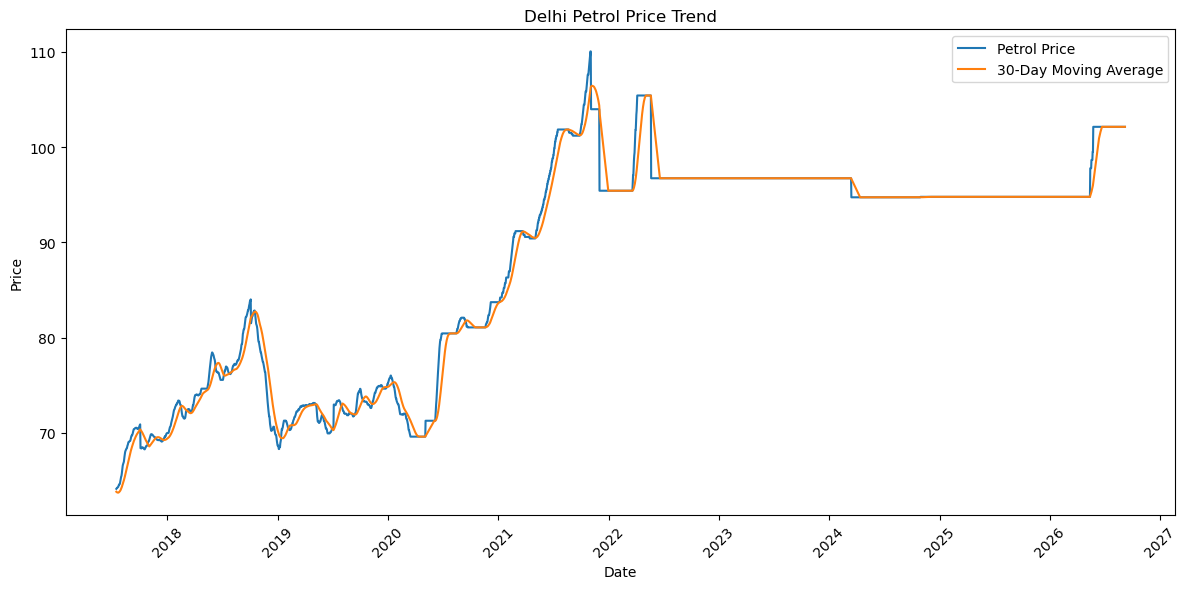

In [41]:
plt.figure(figsize=(12, 6))

plt.plot(
    df["date"],
    df["petrol_price"],
    label="Petrol Price"
)

plt.plot(
    df["date"],
    df["petrol_ma_30"],
    label="30-Day Moving Average"
)

plt.title(
    "Delhi Petrol Price Trend"
)

plt.xlabel("Date")
plt.ylabel("Price")

plt.legend()

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [42]:
OUTPUT_FILE.parent.mkdir(
    parents=True,
    exist_ok=True
)

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print(
    "Processed Delhi Petrol dataset saved successfully!"
)

print(
    "Location:",
    OUTPUT_FILE
)

print(
    "Rows:",
    len(df)
)

print(
    "Columns:",
    len(df.columns)
)

Processed Delhi Petrol dataset saved successfully!
Location: c:\Users\madhu\OneDrive\Documents\FINAURA\data\processed\delhi_petrol_processed.csv
Rows: 3341
Columns: 17
